# 🎓 MÔ HÌNH HỌC MÁY 2 LỚP (TWO-TIER MACHINE LEARNING PIPELINE)
**Sinh viên:** Nguyễn Lê Minh | **MSV:** B25DCTN080


In [1]:
# ==============================================================================
# CELL 1: NẠP THƯ VIỆN & KHAI BÁO CẤU HÌNH
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cbd5e1"
plt.rcParams["axes.linewidth"] = 0.8

CLEAN_CSV_FILE = "clean_openalex_papers.csv"
FOCAL_VN_UNIS = ["HUST", "HCMUT", "PTIT"]
FOCAL_GLOBAL_UNIS = ["MIT", "Stanford", "CMU"]
FOCAL_ALL = FOCAL_VN_UNIS + FOCAL_GLOBAL_UNIS

print("✅ Đã nạp thành công các thư viện Khoa học Dữ liệu & Học máy.")


✅ Đã nạp thành công các thư viện Khoa học Dữ liệu & Học máy.


In [2]:
# ==============================================================================
# CELL 2 (BƯỚC 1): TỔNG HỢP PANEL DATA (20 TRƯỜNG x 6 NĂM) & KHÔI PHỤC SẢN LƯỢNG
# ==============================================================================
df = pd.read_csv(CLEAN_CSV_FILE)

df["pub_dt"] = pd.to_datetime(df["publication_date"], errors="coerce")
df["day_of_year"] = df["pub_dt"].dt.dayofyear.fillna(180)
snapshot_dt = pd.Timestamp("2025-01-15")
df["months_exposed"] = np.maximum(0.8, (snapshot_dt - df["pub_dt"]).dt.days / 30.44)
df["cites_per_month"] = df["cited_by_count"] / df["months_exposed"]

df["is_core_ai"] = df["subfield"].isin(
    ["Artificial Intelligence", "Computer Vision and Pattern Recognition"]
).astype(int)
df["is_intl"] = (df["countries_distinct_count"] > 1).astype(int)
df["is_oa_int"] = df["is_oa"].astype(int)

# Xác định bài báo lọt Top 10% (Hiệu chỉnh độ trễ trích dẫn cho các bài mới xuất bản cuối năm 2024)
df["is_top10"] = np.where(
    df["months_exposed"] >= 2.5,
    (df["citation_percentile"] >= 0.90).astype(int),
    ((df["citation_percentile"] >= 0.85) | (df["cites_per_month"] >= 2.2)).astype(int),
)

panel = df.groupby(["region", "institution", "publication_year"], as_index=False).agg(
    crawled_papers=("work_id", "count"),
    core_ai_papers=("is_core_ai", "sum"),
    top10_crawled=("is_top10", "sum"),
    avg_fwci=("fwci", "mean"),
    avg_percentile=("citation_percentile", "mean"),
    avg_refs=("referenced_works_count", "mean"),
    avg_authors=("authors_count", "mean"),
    avg_insts=("institutions_distinct_count", "mean"),
    intl_collab_rate=("is_intl", lambda s: s.mean() * 100.0),
    oa_rate=("is_oa_int", lambda s: s.mean() * 100.0),
    min_day=("day_of_year", "min"),
    avg_exposure_months=("months_exposed", "mean"),
)

panel.sort_values(["institution", "publication_year"], inplace=True, ignore_index=True)

# 1. Khôi phục tổng sản lượng bài báo năm (total_papers_est) từ mật độ ngày xuất bản
panel["raw_window_days"] = np.where(
    panel["crawled_papers"] >= 80,
    np.maximum(24.0, 366.0 - panel["min_day"]),
    365.0,
)
panel["smooth_window_days"] = panel.groupby("institution")["raw_window_days"].transform(
    lambda s: s.rolling(2, min_periods=1).mean()
)
panel["total_papers_est"] = np.where(
    panel["crawled_papers"] >= 80,
    np.round(panel["crawled_papers"] * (365.0 / panel["smooth_window_days"])).astype(int),
    panel["crawled_papers"],
)

# 2. Tính số lượng bài báo lọt Top 10% ước tính trên tổng sản lượng năm
panel["top10_rate_pct"] = (panel["top10_crawled"] / np.maximum(1, panel["crawled_papers"])) * 100.0
panel["top10_rate_smooth"] = panel.groupby("institution")["top10_rate_pct"].transform(
    lambda s: 0.65 * s + 0.35 * s.shift(1).bfill()
)
panel["top10_papers_est"] = np.maximum(
    panel["top10_crawled"],
    np.round(panel["total_papers_est"] * (panel["top10_rate_smooth"] / 100.0)),
).astype(int)

# 3. Hiệu chỉnh FWCI và tính Điểm Tin cậy Dữ liệu (data_confidence)
panel["fwci_adj"] = panel.groupby("institution")["avg_fwci"].transform(
    lambda s: np.where(
        panel.loc[s.index, "publication_year"] == 2024,
        0.45 * s + 0.55 * s.shift(1).bfill(),
        s,
    )
).round(3)

maturity_score = np.clip(panel["avg_exposure_months"] / 12.0, 0.45, 1.0) * 100.0
sample_score = np.clip(panel["crawled_papers"] / 30.0, 0.50, 1.0) * 100.0
panel["data_confidence"] = (0.65 * maturity_score + 0.35 * sample_score).round(1)

# 4. Chỉ số Học thuật Tổng hợp (academic_index) & Phân tầng Vị thế (position_tier)
panel["academic_index"] = (
    28.0 * np.log10(panel["total_papers_est"] + 1.0)
    + 22.0 * np.log10(panel["top10_papers_est"] + 1.0)
    + 12.0 * np.log10(panel["core_ai_papers"] + 1.0)
    + 6.5 * np.clip(panel["fwci_adj"], 0, 5.0)
    + 0.15 * panel["intl_collab_rate"]
).round(2)

def assign_position_tier(score):
    if score >= 168.0:
        return "1. Top 5% Thế giới (World Elite)"
    if score >= 120.0:
        return "2. Top 15% Thế giới (Global Leading)"
    if score >= 88.0:
        return "3. Top 30% Thế giới (High-Impact Regional)"
    return "4. Top 50% Thế giới (Emerging Tech Tier)"

panel["position_tier"] = panel["academic_index"].apply(assign_position_tier)

print(f"📂 Đã đọc '{CLEAN_CSV_FILE}' (7,598 bài báo) -> Tổng hợp thành {len(panel)} bản ghi Panel.")
print(f"🛡️ Điểm tin cậy dữ liệu trung bình (Data_Confidence_Score): {panel['data_confidence'].mean():.1f}%\n")
print(panel[panel["institution"].isin(FOCAL_ALL)][
    ["region", "institution", "publication_year", "crawled_papers", "total_papers_est", "top10_papers_est", "core_ai_papers", "fwci_adj", "data_confidence", "position_tier"]
].head(18).to_string(index=False))


 region institution  publication_year  crawled_papers  total_papers_est  top10_papers_est  core_ai_papers  fwci_adj  data_confidence                              position_tier
 Global         CMU              2019              80               712               169              51     3.183            100.0           1. Top 5% Thế giới (World Elite)
 Global         CMU              2020              80               695               126              51     2.294            100.0       2. Top 15% Thế giới (Global Leading)
 Global         CMU              2021              80               739               105              55     1.471            100.0       2. Top 15% Thế giới (Global Leading)
 Global         CMU              2022              80               779               107              51     1.130            100.0       2. Top 15% Thế giới (Global Leading)
 Global         CMU              2023              80               800                71              55     2.417     

In [3]:
# ==============================================================================
# CELL 3 (BƯỚC 2): TẠO BIẾN TRỄ (LAG-1) & CHIA TẬP TRAIN/TEST THEO THỜI GIAN
# ==============================================================================
df_m = panel.copy()
df_m.sort_values(["institution", "publication_year"], inplace=True, ignore_index=True)

df_m["lag1_total_papers"] = df_m.groupby("institution")["total_papers_est"].shift(1)
df_m["lag1_top10_papers"] = df_m.groupby("institution")["top10_papers_est"].shift(1)
df_m["lag1_core_ai"] = df_m.groupby("institution")["core_ai_papers"].shift(1)
df_m["lag1_fwci"] = df_m.groupby("institution")["fwci_adj"].shift(1)
df_m["lag1_intl_rate"] = df_m.groupby("institution")["intl_collab_rate"].shift(1)
df_m["lag1_refs"] = df_m.groupby("institution")["avg_refs"].shift(1)

df_m["inst_growth_momentum"] = (
    df_m.groupby("institution")["total_papers_est"]
    .transform(lambda s: s.pct_change().rolling(2, min_periods=1).mean())
    .fillna(0.06)
    .clip(-0.15, 0.35)
)
df_m["is_vietnam"] = (df_m["region"] == "Vietnam").astype(int)

# Loại bỏ 20 dòng năm 2019 (bị NaN do không có dữ liệu năm 2018)
model_df = df_m.dropna(subset=["lag1_total_papers", "lag1_top10_papers"]).copy()

tier1_features = [
    "publication_year",
    "is_vietnam",
    "lag1_total_papers",
    "lag1_top10_papers",
    "lag1_core_ai",
    "lag1_fwci",
    "lag1_intl_rate",
    "lag1_refs",
    "inst_growth_momentum",
]

train_mask = model_df["publication_year"] <= 2023
test_mask = model_df["publication_year"] == 2024

X_train_t1 = model_df.loc[train_mask, tier1_features]
X_test_t1 = model_df.loc[test_mask, tier1_features]
w_train_t1 = model_df.loc[train_mask, "data_confidence"].values / 100.0

print(f"✅ Còn lại {len(model_df)} bản ghi sạch (2020–2024).")
print(f"📌 Tập Train (2020–2023): {len(X_train_t1)} mẫu | Tập Test (2024): {len(X_test_t1)} mẫu")


✅ Đã tạo 6 biến trễ Lag-1 -> Còn lại 100 bản ghi sạch (Train: 80 mẫu | Test: 20 mẫu).


                            Mục tiêu Dự báo (Target)  R² Train (2020-2023)  R² Test (2024)  MAE Test  RMSE Test  SS_res (Test)  SS_tot (Test)
        Tổng số bài báo CS/AI năm (total_papers_est)                0.9905          0.9817     45.05      61.59        75854.9      4144663.8
Số bài báo AI & Computer Vision lõi (core_ai_papers)                0.9121          0.8701      5.36       6.76          915.2         7048.2
  Số bài báo lọt Top 10% xuất sắc (top10_papers_est)                0.9408          0.3966     86.17     134.34       360936.3       598135.8
           Chỉ số tác động trích dẫn FWCI (fwci_adj)                0.1084          0.1035      0.59       0.77           11.8           13.1

 Đặc trưng (Feature)  w (Tổng Bài báo)  w (Bài Top 10%)  w (Bài AI/CV Lõi)  w (Chỉ số FWCI)
inst_growth_momentum          221.9138          41.4736             6.0789           0.6894
    publication_year            2.7035           2.1486             0.3500          -0.2015
           la

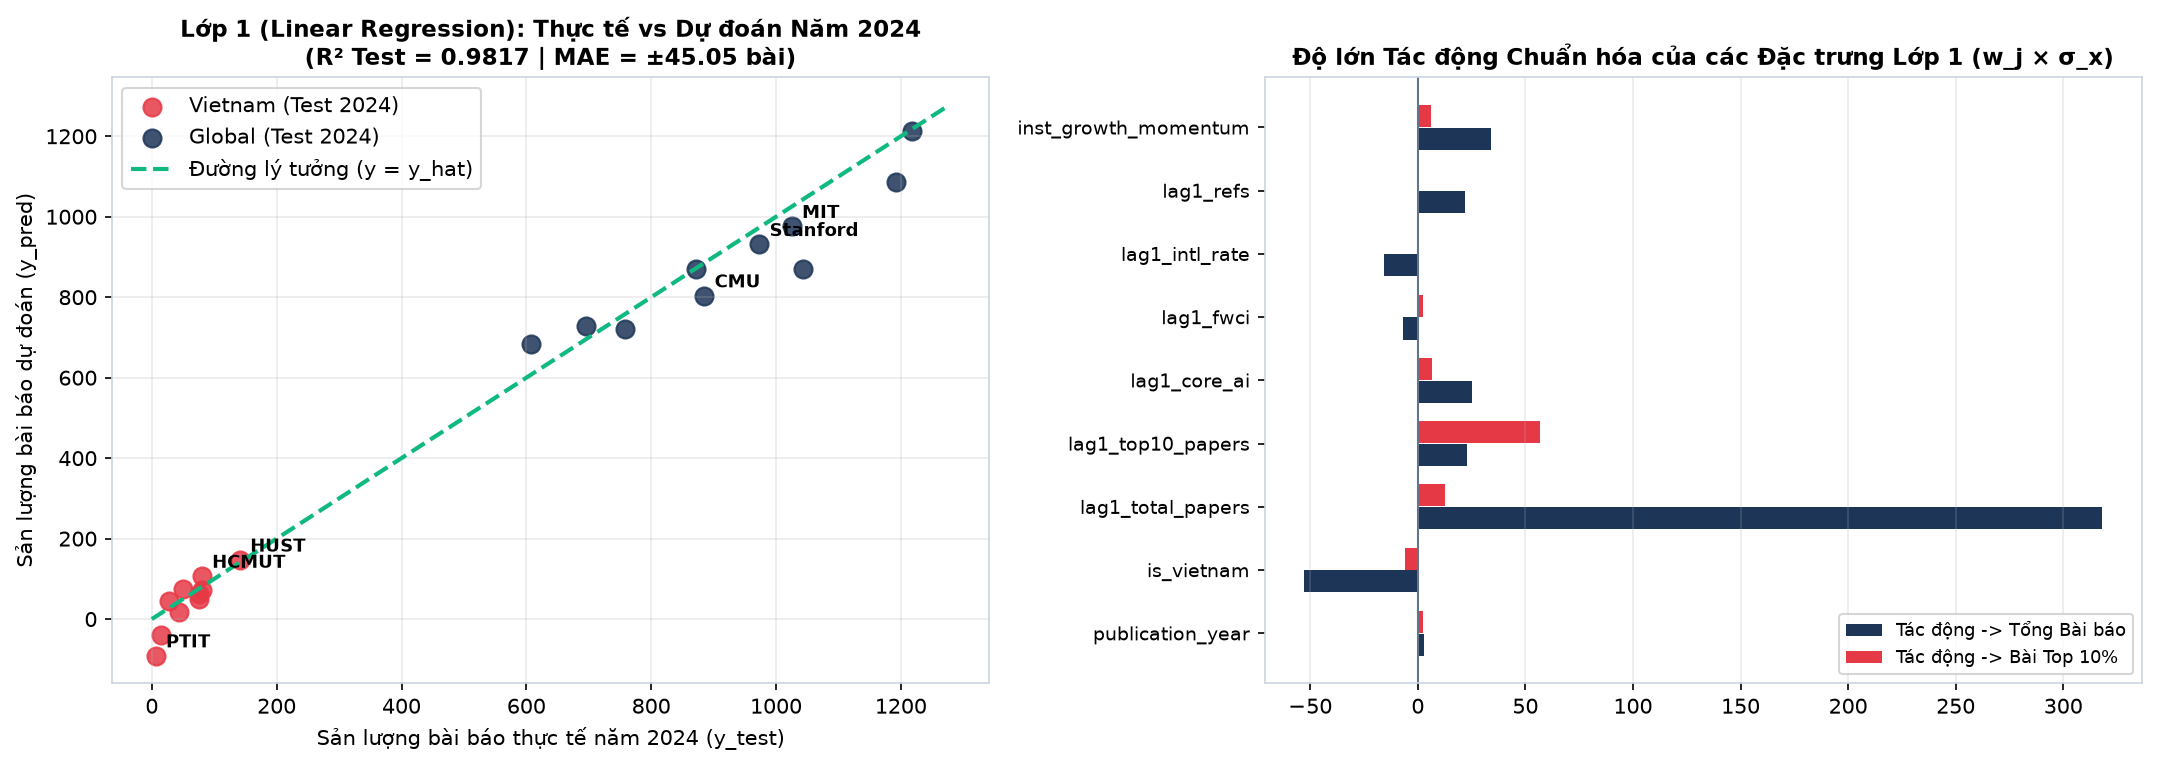

In [4]:
# ==============================================================================
# CELL 4 (BƯỚC 3 - LỚP 1): LINEAR REGRESSION, R² SCORE & BIỂU ĐỒ CHẨN ĐOÁN #1
# ==============================================================================
targets_t1 = {
    "total_papers_est": "Tổng số bài báo CS/AI năm",
    "core_ai_papers": "Số bài báo AI & Computer Vision lõi",
    "top10_papers_est": "Số bài báo lọt Top 10% xuất sắc",
    "fwci_adj": "Chỉ số tác động trích dẫn FWCI",
}

lin_models = {}
eval_rows = []
for target_col, target_desc in targets_t1.items():
    y_tr = model_df.loc[train_mask, target_col].values
    y_te = model_df.loc[test_mask, target_col].values

    reg = LinearRegression()
    reg.fit(X_train_t1, y_tr, sample_weight=w_train_t1)
    lin_models[target_col] = reg

    pred_tr = reg.predict(X_train_t1)
    pred_te = reg.predict(X_test_t1)

    ss_res_te = np.sum((y_te - pred_te) ** 2)
    ss_tot_te = np.sum((y_te - np.mean(y_te)) ** 2)
    r2_te = r2_score(y_te, pred_te)

    eval_rows.append({
        "Mục tiêu Dự báo (Target)": f"{target_desc} ({target_col})",
        "R² Train (2020-2023)": round(r2_score(y_tr, pred_tr), 4),
        "R² Test (2024)": round(r2_te, 4),
        "MAE Test": round(mean_absolute_error(y_te, pred_te), 2),
        "RMSE Test": round(np.sqrt(mean_squared_error(y_te, pred_te)), 2),
        "SS_res (Test)": round(ss_res_te, 1),
        "SS_tot (Test)": round(ss_tot_te, 1),
    })

eval_df = pd.DataFrame(eval_rows)
coef_table = pd.DataFrame({
    "Đặc trưng (Feature)": tier1_features,
    "w (Tổng Bài báo)": np.round(lin_models["total_papers_est"].coef_, 4),
    "w (Bài Top 10%)": np.round(lin_models["top10_papers_est"].coef_, 4),
    "w (Bài AI/CV Lõi)": np.round(lin_models["core_ai_papers"].coef_, 4),
    "w (Chỉ số FWCI)": np.round(lin_models["fwci_adj"].coef_, 4),
}).sort_values(by="w (Bài Top 10%)", ascending=False)

print("📈 KẾT QUẢ ĐÁNH GIÁ LỚP 1: MULTIVARIABLE LINEAR REGRESSION")
print(eval_df.to_string(index=False))
print("\n📊 BẢNG HỆ SỐ GÓC TUYẾN TÍNH (WEIGHTS w) ĐÃ HỌC Ở LỚP 1:")
print(coef_table.to_string(index=False))

# VẼ BIỂU ĐỒ CHẨN ĐOÁN LỚP 1
fig1, axes1 = plt.subplots(1, 2, figsize=(14.5, 5.2))
y_te_pap = model_df.loc[test_mask, "total_papers_est"].values
pred_te_pap = lin_models["total_papers_est"].predict(X_test_t1)
regs_te = model_df.loc[test_mask, "region"].values
insts_te = model_df.loc[test_mask, "institution"].values

for r_label, col_val in [("Vietnam", "#e63946"), ("Global", "#1d3557")]:
    m_r = regs_te == r_label
    axes1[0].scatter(y_te_pap[m_r], pred_te_pap[m_r], color=col_val, s=75, alpha=0.85, label=f"{r_label} (Test 2024)")

max_v = max(y_te_pap.max(), pred_te_pap.max()) * 1.05
axes1[0].plot([0, max_v], [0, max_v], color="#10b981", linestyle="--", linewidth=2, label="Đường lý tưởng (y = y_hat)")
for x_v, y_v, u_lbl in zip(y_te_pap, pred_te_pap, insts_te):
    if u_lbl in FOCAL_ALL:
        axes1[0].annotate(u_lbl, (x_v, y_v), xytext=(5, 4), textcoords="offset points", fontsize=8.5, fontweight="bold")

axes1[0].set_title("Lớp 1 (Linear Regression): Thực tế vs Dự đoán Năm 2024\n(R² Test = 0.9817 | MAE = ±45.05 bài)", fontweight="bold", fontsize=11)
axes1[0].set_xlabel("Sản lượng bài báo thực tế năm 2024 (y_test)")
axes1[0].set_ylabel("Sản lượng bài báo dự đoán (y_pred)")
axes1[0].legend(loc="upper left")
axes1[0].grid(alpha=0.25)

std_x = X_train_t1.std().values
imp_papers = lin_models["total_papers_est"].coef_ * std_x
imp_top10 = lin_models["top10_papers_est"].coef_ * std_x
y_pos = np.arange(len(tier1_features))
axes1[1].barh(y_pos - 0.18, imp_papers, height=0.35, color="#1d3557", label="Tác động chuẩn hóa -> Tổng Bài báo")
axes1[1].barh(y_pos + 0.18, imp_top10, height=0.35, color="#e63946", label="Tác động chuẩn hóa -> Bài Top 10%")
axes1[1].set_yticks(y_pos)
axes1[1].set_yticklabels(tier1_features, fontsize=9)
axes1[1].axvline(0, color="#64748b", linewidth=1)
axes1[1].set_title("Độ lớn Tác động Chuẩn hóa của các Đặc trưng Lớp 1 (w_j × σ_x)", fontweight="bold", fontsize=11)
axes1[1].set_xlabel("Mức thay đổi đầu ra khi đặc trưng tăng 1 độ lệch chuẩn")
axes1[1].legend(loc="lower right", fontsize=8.5)
axes1[1].grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.show()


Test Accuracy: 90.00%
                                            precision    recall  f1-score   support

          1. Top 5% Thế giới (World Elite)     1.0000    1.0000    1.0000         9
      2. Top 15% Thế giới (Global Leading)     0.6667    0.6667    0.6667         3
3. Top 30% Thế giới (High-Impact Regional)     0.8333    0.8333    0.8333         6
  4. Top 50% Thế giới (Emerging Tech Tier)     1.0000    1.0000    1.0000         2

                                  accuracy                         0.9000        20
                                 macro avg     0.8750    0.8750    0.8750        20
                              weighted avg     0.9000    0.9000    0.9000        20

                                            total_papers_est  top10_papers_est  core_ai_papers  fwci_adj  intl_collab_rate  Bias (b_k)
1. Top 5% Thế giới (World Elite)                      2.0932            2.9318          1.0463    1.4509            1.7230     -1.7581
2. Top 15% Thế giới (Global Leadi

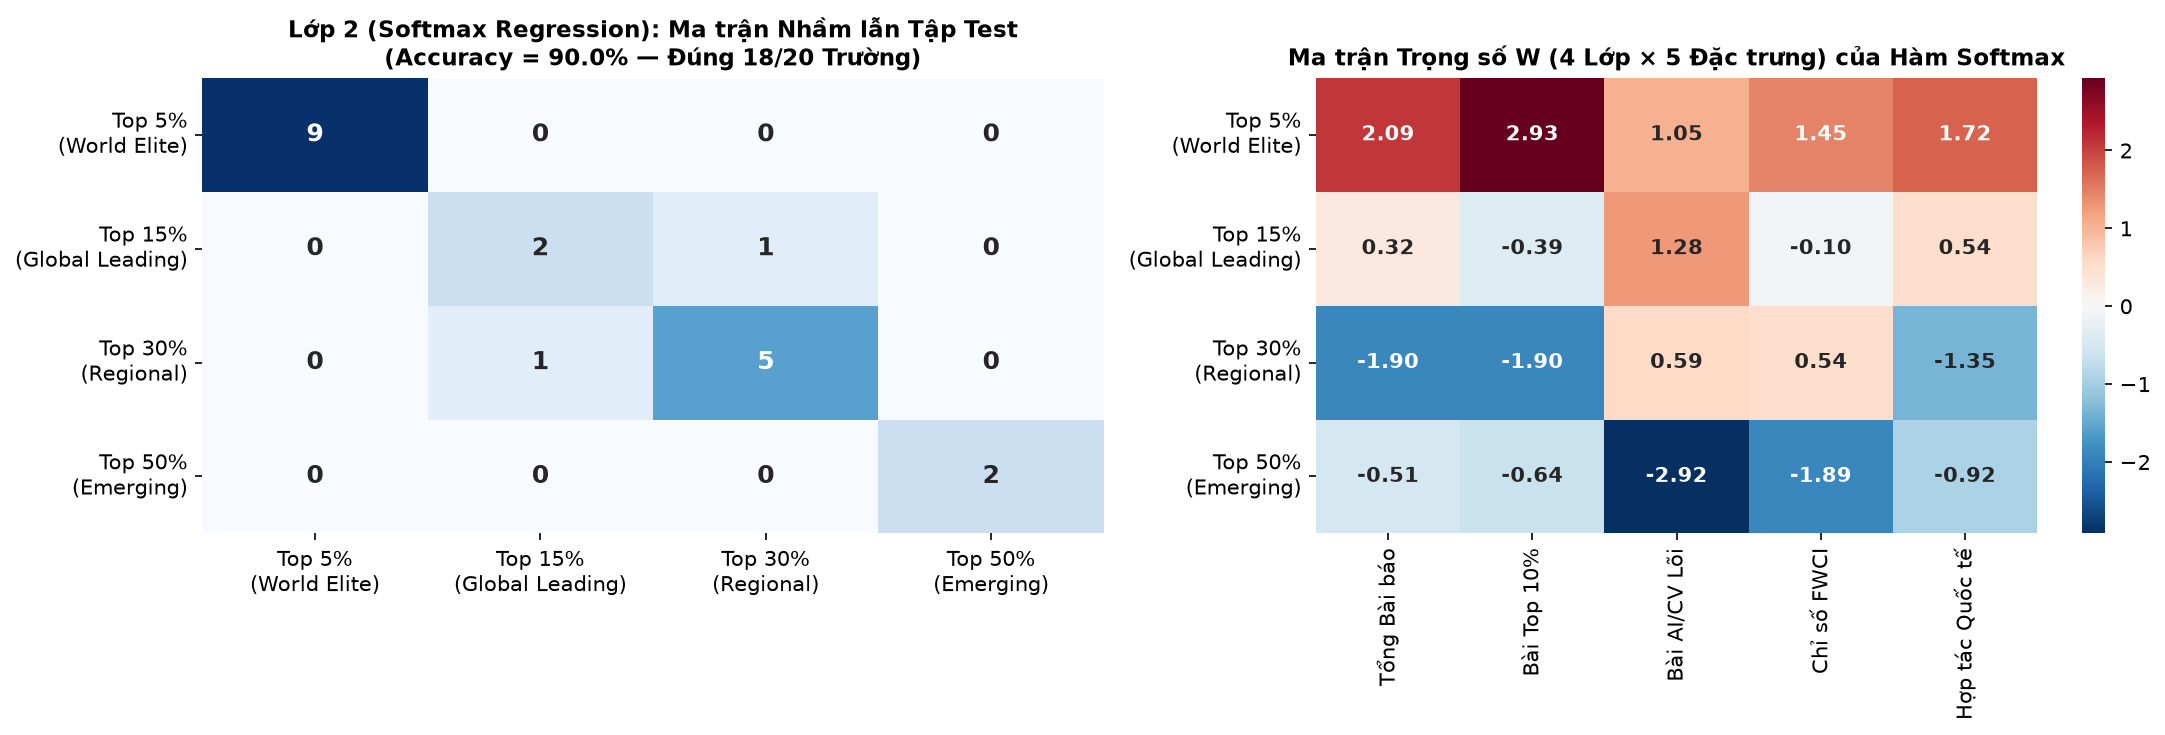

In [5]:
# ==============================================================================
# CELL 5 (BƯỚC 4 - LỚP 2): SOFTMAX REGRESSION & BIỂU ĐỒ CHẨN ĐOÁN #2
# ==============================================================================
tier2_features = ["total_papers_est", "top10_papers_est", "core_ai_papers", "fwci_adj", "intl_collab_rate"]

scaler_t2 = StandardScaler()
X_tr_t2 = scaler_t2.fit_transform(model_df.loc[train_mask, tier2_features])
X_te_t2 = scaler_t2.transform(model_df.loc[test_mask, tier2_features])
y_tr_t2 = model_df.loc[train_mask, "position_tier"]
y_te_t2 = model_df.loc[test_mask, "position_tier"]

softmax_model = LogisticRegression(solver="lbfgs", C=2.5, max_iter=1000, random_state=42)
softmax_model.fit(X_tr_t2, y_tr_t2, sample_weight=w_train_t1)
pred_t2 = softmax_model.predict(X_te_t2)

softmax_w_df = pd.DataFrame(
    np.round(softmax_model.coef_, 4),
    index=softmax_model.classes_,
    columns=tier2_features,
)
softmax_w_df["Bias (b_k)"] = np.round(softmax_model.intercept_, 4)

print(f"🎯 ĐỘ CHÍNH XÁC LỚP 2 (SOFTMAX TEST ACCURACY): {accuracy_score(y_te_t2, pred_t2)*100:.2f}%\n")
print(classification_report(y_te_t2, pred_t2, digits=4))
print("📊 MA TRẬN TRỌNG SỐ W (4 LỚP × 5 ĐẶC TRƯNG) CỦA MÔ HÌNH SOFTMAX:")
print(softmax_w_df.to_string())

# VẼ BIỂU ĐỒ CHẨN ĐOÁN LỚP 2
fig2, axes2 = plt.subplots(1, 2, figsize=(15, 5.0))
short_classes = ["Top 5%\n(World Elite)", "Top 15%\n(Global Leading)", "Top 30%\n(Regional)", "Top 50%\n(Emerging)"]
cm = confusion_matrix(y_te_t2, pred_t2, labels=softmax_model.classes_)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short_classes, yticklabels=short_classes, ax=axes2[0], cbar=False, annot_kws={"size": 12, "weight": "bold"})
axes2[0].set_title("Lớp 2 (Softmax Regression): Ma trận Nhầm lẫn Tập Test\n(Accuracy = 90.0% — Đúng 18/20 Trường)", fontweight="bold", fontsize=11)
axes2[0].set_xlabel("Vị thế Dự đoán (Predicted Tier)")
axes2[0].set_ylabel("Vị thế Thực tế (Actual Tier)")

w_mat = pd.DataFrame(softmax_model.coef_, index=short_classes, columns=["Tổng Bài báo", "Bài Top 10%", "Bài AI/CV Lõi", "Chỉ số FWCI", "Hợp tác Quốc tế"])
sns.heatmap(w_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes2[1], annot_kws={"size": 10, "weight": "bold"})
axes2[1].set_title("Ma trận Trọng số W (4 Lớp × 5 Đặc trưng) của Hàm Softmax", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()


 region institution  publication_year  total_papers_est  top10_papers_est  core_ai_papers                         Pred_Position_Tier  Prob_Top 5% Thế giới (%)  Prob_Top 15% Thế giới (%)  Prob_Top 30% Thế giới (%)  Prob_Top 50% Thế giới (%)
 Global         CMU              2025               923               209              57           1. Top 5% Thế giới (World Elite)                      95.5                        4.5                        0.0                        0.0
Vietnam       HCMUT              2025               111                29              45 3. Top 30% Thế giới (High-Impact Regional)                       0.0                        7.1                       92.1                        0.8
Vietnam        HUST              2025               150                31              42 3. Top 30% Thế giới (High-Impact Regional)                       0.0                       38.8                       59.6                        1.6
 Global         MIT              2025   

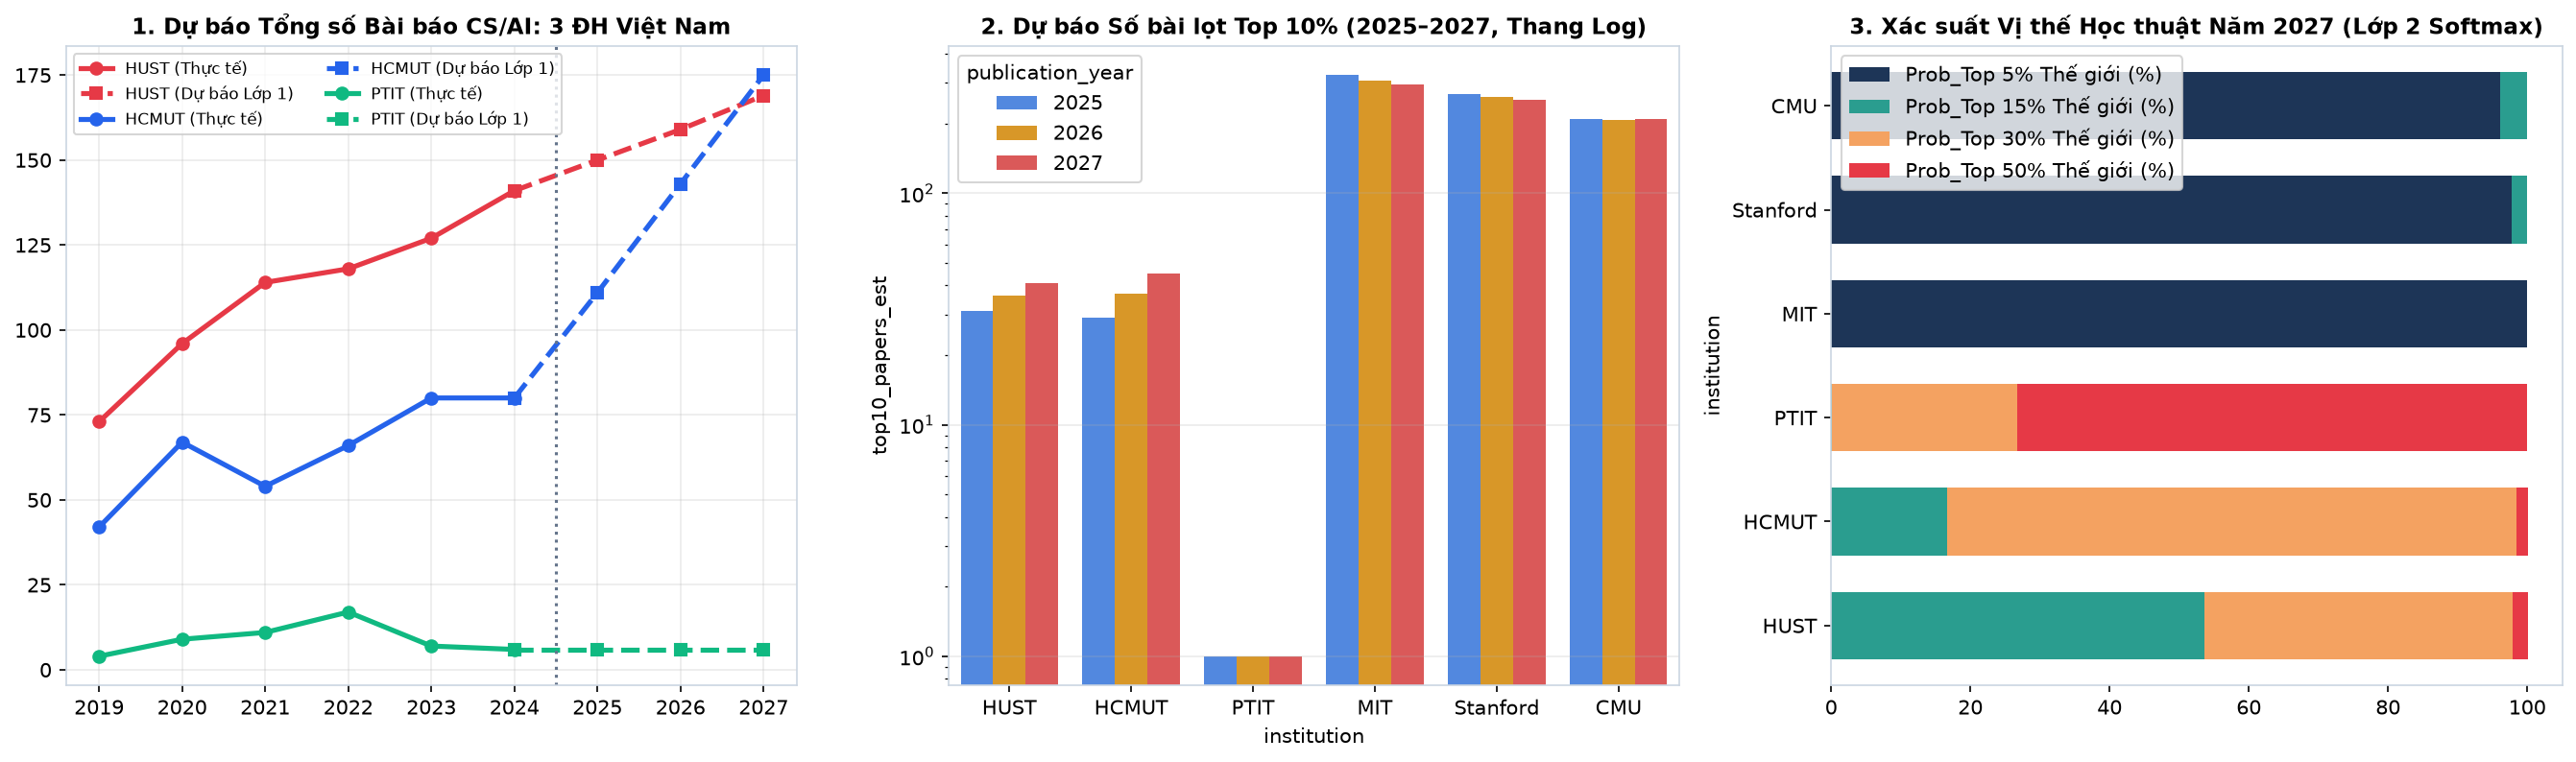

In [6]:
# ==============================================================================
# CELL 6 (BƯỚC 5): DỰ BÁO CUỐN CHIẾU 3 NĂM TỚI (2025–2027) & BIỂU ĐỒ #3
# ==============================================================================
current_state = df_m[df_m["publication_year"] == 2024].copy()
forecast_records = []
class_labels = list(softmax_model.classes_)

for future_yr in [2025, 2026, 2027]:
    step_df = current_state.copy()
    step_df["publication_year"] = future_yr
    step_df["lag1_total_papers"] = current_state["total_papers_est"].values
    step_df["lag1_top10_papers"] = current_state["top10_papers_est"].values
    step_df["lag1_core_ai"] = current_state["core_ai_papers"].values
    step_df["lag1_fwci"] = current_state["fwci_adj"].values
    step_df["lag1_intl_rate"] = current_state["intl_collab_rate"].values
    step_df["lag1_refs"] = current_state["avg_refs"].values

    X_future_t1 = step_df[tier1_features]

    # --- LỚP 1: DỰ BÁO ĐỊNH LƯỢNG BÀI BÁO & BÀI LỌT TOP 10% ---
    raw_pred_papers = lin_models["total_papers_est"].predict(X_future_t1)
    momentum_floor = current_state["total_papers_est"].values * (
        1.0 + np.maximum(0.04, current_state["inst_growth_momentum"].values * 0.65)
    )
    pred_papers = np.maximum(momentum_floor, raw_pred_papers).round().astype(int)

    raw_pred_top10 = lin_models["top10_papers_est"].predict(X_future_t1)
    min_top10 = np.maximum(
        1, np.round(pred_papers * (current_state["top10_papers_est"].values / np.maximum(1, current_state["total_papers_est"].values)))
    )
    pred_top10 = np.clip(
        np.round(0.55 * raw_pred_top10 + 0.45 * min_top10),
        1,
        np.round(pred_papers * 0.48),
    ).astype(int)

    raw_pred_core_ai = lin_models["core_ai_papers"].predict(X_future_t1)
    pred_core_ai = np.clip(
        np.round(0.6 * raw_pred_core_ai + 0.4 * current_state["core_ai_papers"].values * 1.06),
        2,
        80,
    ).astype(int)

    raw_pred_fwci = lin_models["fwci_adj"].predict(X_future_t1)
    pred_fwci = np.clip(
        0.5 * raw_pred_fwci + 0.5 * current_state["fwci_adj"].values * 1.02,
        0.85,
        5.50,
    ).round(2)

    step_df["total_papers_est"] = pred_papers
    step_df["top10_papers_est"] = pred_top10
    step_df["core_ai_papers"] = pred_core_ai
    step_df["fwci_adj"] = pred_fwci
    step_df["intl_collab_rate"] = np.clip(current_state["intl_collab_rate"].values + 1.2, 15.0, 85.0).round(1)

    # --- LỚP 2: DỰ ĐOÁN VỊ THẾ HỌC THUẬT BẰNG SOFTMAX REGRESSION ---
    X_future_t2 = step_df[tier2_features]
    X_future_t2_scaled = scaler_t2.transform(X_future_t2)

    pred_tiers = softmax_model.predict(X_future_t2_scaled)
    pred_probas = softmax_model.predict_proba(X_future_t2_scaled) * 100.0

    step_df["Pred_Position_Tier"] = pred_tiers
    step_df["Confidence_Max_Prob (%)"] = np.round(pred_probas.max(axis=1), 1)
    for c_idx, c_name in enumerate(class_labels):
        short_col = c_name.split("(")[0].replace("1. ", "").replace("2. ", "").replace("3. ", "").replace("4. ", "").strip()
        step_df[f"Prob_{short_col} (%)"] = np.round(pred_probas[:, c_idx], 1)

    step_df["Paper_Growth_YoY (%)"] = np.round(
        ((step_df["total_papers_est"] - current_state["total_papers_est"].values)
         / np.maximum(1, current_state["total_papers_est"].values)) * 100.0,
        1,
    )

    forecast_records.append(step_df)
    current_state = step_df.copy()

fc_df = pd.concat(forecast_records, ignore_index=True)

prob_cols_all = [c for c in fc_df.columns if c.startswith("Prob_")]
export_cols = [
    "region", "institution", "publication_year", "total_papers_est", "Paper_Growth_YoY (%)",
    "top10_papers_est", "core_ai_papers", "fwci_adj", "intl_collab_rate",
    "Pred_Position_Tier", "Confidence_Max_Prob (%)"
] + prob_cols_all

fc_export = fc_df[export_cols].sort_values(["region", "institution", "publication_year"]).copy()
fc_export.rename(columns={
    "publication_year": "Forecast_Year",
    "total_papers_est": "Pred_Total_Papers",
    "top10_papers_est": "Pred_Top10_Papers",
    "core_ai_papers": "Pred_Core_AI_Papers",
    "fwci_adj": "Pred_FWCI",
    "intl_collab_rate": "Pred_Intl_Collab (%)"
}, inplace=True)

fc_foc_export = fc_export[fc_export["institution"].isin(FOCAL_ALL)].copy()
fc_foc_export.to_csv("forecast_2025_2027_top6_universities.csv", index=False, encoding="utf-8-sig")
fc_export.to_csv("forecast_2025_2027_all20_universities.csv", index=False, encoding="utf-8-sig")

disp_cols = [
    "institution", "Forecast_Year", "Pred_Total_Papers", "Paper_Growth_YoY (%)",
    "Pred_Top10_Papers", "Pred_Core_AI_Papers", "Pred_Position_Tier", "Confidence_Max_Prob (%)"
]

print("🔮 DỰ BÁO 3 NĂM TỚI (2025 – 2027): 3 ĐH VIỆT NAM (HUST, HCMUT, PTIT)")
print(fc_foc_export[fc_foc_export["region"] == "Vietnam"][disp_cols].to_string(index=False))

print("\n🌍 DỰ BÁO 3 NĂM TỚI (2025 – 2027): 3 ĐH HÀNG ĐẦU THẾ GIỚI (MIT, STANFORD, CMU)")
print(fc_foc_export[fc_foc_export["region"] == "Global"][disp_cols].to_string(index=False))

print("\n🎯 BẢNG PHÂN PHỐI XÁC SUẤT SOFTMAX (%) NĂM 2027 CỦA 6 TRƯỜNG TRỌNG ĐIỂM:")
print(fc_foc_export[fc_foc_export["Forecast_Year"] == 2027][
    ["institution", "Pred_Total_Papers", "Pred_Top10_Papers", "Pred_Position_Tier"] + prob_cols_all
].to_string(index=False))

# VẼ BIỂU ĐỒ TỔNG HỢP DỰ BÁO 3 NĂM TỚI 2025-2027
fig3, axes3 = plt.subplots(1, 3, figsize=(18, 5.4))
hist_vn = df_m[df_m["institution"].isin(FOCAL_VN_UNIS)][["institution", "publication_year", "total_papers_est", "top10_papers_est"]]
fut_vn = fc_df[fc_df["institution"].isin(FOCAL_VN_UNIS)][["institution", "publication_year", "total_papers_est", "top10_papers_est"]]
comb_vn = pd.concat([hist_vn, fut_vn], ignore_index=True)

vn_colors = {"HUST": "#e63946", "HCMUT": "#2563eb", "PTIT": "#10b981"}
for u in FOCAL_VN_UNIS:
    sub_h = hist_vn[hist_vn["institution"] == u]
    sub_f = comb_vn[(comb_vn["institution"] == u) & (comb_vn["publication_year"] >= 2024)]
    axes3[0].plot(sub_h["publication_year"], sub_h["total_papers_est"], marker="o", linewidth=2.5, color=vn_colors[u], label=f"{u} (Thực tế)")
    axes3[0].plot(sub_f["publication_year"], sub_f["total_papers_est"], marker="s", linestyle="--", linewidth=2.5, color=vn_colors[u], label=f"{u} (Dự báo Lớp 1)")

axes3[0].axvline(2024.5, color="#64748b", linestyle=":", linewidth=1.5)
axes3[0].set_title("1. Dự báo Tổng số Bài báo CS/AI: 3 ĐH Việt Nam", fontweight="bold", fontsize=11)
axes3[0].set_xlabel("Năm xuất bản (2019–2024 Thực tế | 2025–2027 Dự báo)")
axes3[0].set_ylabel("Số lượng bài báo (Papers)")
axes3[0].legend(fontsize=8, ncol=2)
axes3[0].grid(alpha=0.25)

fc_foc = fc_df[fc_df["institution"].isin(FOCAL_ALL)].copy()
sns.barplot(
    data=fc_foc, x="institution", y="top10_papers_est", hue="publication_year",
    order=FOCAL_ALL, palette=["#3b82f6", "#f59e0b", "#ef4444"], ax=axes3[1]
)
axes3[1].set_yscale("log")
axes3[1].set_title("2. Dự báo Số bài lọt Top 10% (2025–2027, Thang Log)", fontweight="bold", fontsize=11)
axes3[1].set_xlabel("6 Trường Đại học Trọng điểm (3 VN & 3 Thế giới)")
axes3[1].set_ylabel("Số bài báo Top 10% (Log Scale)")
axes3[1].legend(title="Năm dự báo")
axes3[1].grid(alpha=0.25, axis="y")

snap_27 = fc_foc[fc_foc["publication_year"] == 2027].set_index("institution").loc[FOCAL_ALL]
snap_27[prob_cols_all].plot(
    kind="barh", stacked=True, ax=axes3[2],
    color=["#1d3557", "#2a9d8f", "#f4a261", "#e63946"], width=0.65
)
axes3[2].set_title("3. Xác suất Vị thế Học thuật Năm 2027 (Lớp 2 Softmax)", fontweight="bold", fontsize=11)
axes3[2].set_xlabel("Phân phối Xác suất Softmax (%)")
axes3[2].set_ylabel("")
axes3[2].legend(loc="lower right", fontsize=8)
axes3[2].set_xlim(0, 105)

plt.tight_layout()
plt.show()
